## Classe B : Sequenza principale

In [1]:
import sys
sys.path.append('../../../src')
import spectrum as spec
import pandas as pd

In [2]:
spectra_files = [("_sigmacas_20250919_785-rect.fit","Sigma Cas B1V", 1, "line_measured_sigma_cas_20250919.csv", 21000), 
                 ("_furud_20260222_748-rect.fit","Furud B2.5V", 2.5, "line_measured_furud_20260222.csv", 18700), 
                 ("_alkaid_20250808_874-rect.fit","Alkaid B3V", 3, "line_measured_alkaid_20250808.csv", 16800),
                 ("_2lac_20251212_738-rect.fit","2 Lac B6V", 6, "line_measured_2_lac_20251212.csv", 15000),
                 ("_celaeno_20260221_816-rect.fit","Celaeno B7V", 7, "line_measured_celaeno_20260221.csv", 12800),
                 ("_algol_20251209_719-rect.fit","Algol B8V", 8, "line_measured_algol_20251209.csv", 12550)]
spectra = []
for fit_file_name, label, temp_index, measures_file_name, eff_temp in spectra_files:
    wl, flux = spec.load(fit_file_name)
    spectra.append((wl, flux, label, temp_index, eff_temp))

spectral_lines = pd.read_csv('line_list.csv', usecols=[0, 1, 2], names=["name","class","wavelength"])

In [3]:
import numpy as np
import matplotlib.pyplot as plt

def multi_plot(spectra, spectral_lines, dist=0.5, title = "", wl_range = (3700,6800), flux_range=(0.2,1.1)):
    wlmin, wlmax = wl_range
    ymin, ymax = flux_range
    plt.figure(figsize=(12,12))
    delta_flux = 0.0
    for wavelength, flux, label, _, _ in spectra:
        plt.plot(wavelength, flux + delta_flux, color="blue", lw=0.5)
        plt.text(
                wlmax * (0.995),
                delta_flux + 1.015,
                label,
                verticalalignment="bottom",
                horizontalalignment="right",
                fontsize=9,
                color="black"
            )
        delta_flux = delta_flux + dist

    for index, row in spectral_lines.iterrows():
        name = row["name"]
        lin_ident_class = row["class"]
        lam_obs = row["wavelength"]
        
        if (wlmin < lam_obs < wlmax) & (isinstance(name, str)):
            #print(name, lam_rest, lin_ident_class)
            lin_col = "green"
            plt.axvline(lam_obs, color=lin_col, alpha=0.4, lw=1, ls="--", ymax=(ymax+delta_flux-dist-ymin)/(ymax+delta_flux-ymin))
            plt.text(
                lam_obs,
                ymax+delta_flux-ymin-dist/2.0,
                name.replace(r'\n', '\n'),
                rotation=90,
                verticalalignment="bottom",
                horizontalalignment="center",
                fontsize=9,
                color=lin_col
            )
    
    plt.ylim(ymin, ymax+delta_flux)
    plt.xlim(wlmin,wlmax)

    plt.xlabel("Wavelength (Angstrom)")
    plt.ylabel("Flux")
    plt.title(title)

    plt.grid(alpha=0.3)
    #plt.tight_layout()
    plt.show()

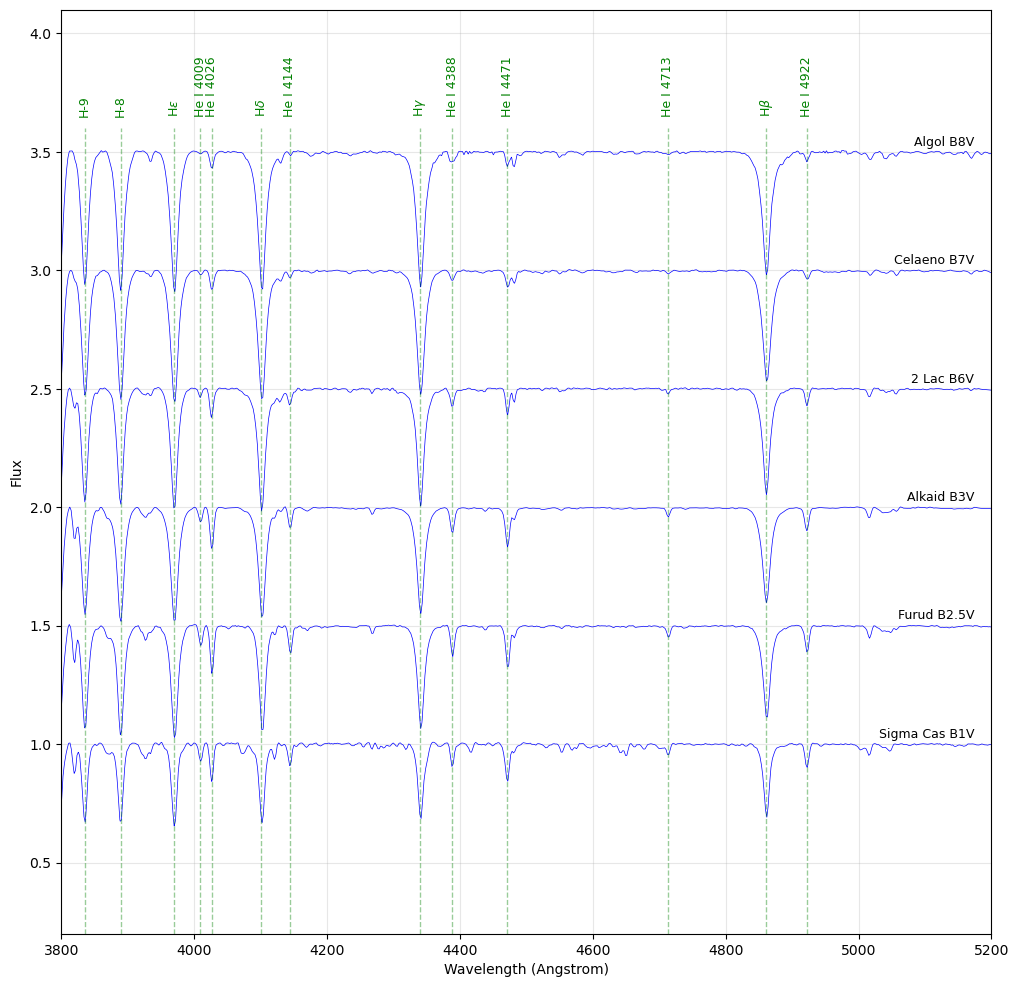

In [4]:
multi_plot(spectra, spectral_lines, wl_range = (3800,5200))

In [5]:
star_measures = []

for fit_file_name, label, temp_index, measures_file_name, eff_temp in spectra_files:
    df = pd.read_csv(measures_file_name)
    df["temp index"] = temp_index
    df["eff_temp"] = eff_temp
    df = df[df["line_name"].apply(lambda s: not s.lower().startswith("unknown"))]
    star_measures.append(df)

all_measures = pd.concat(star_measures, ignore_index=True)
all_measures["intensity"] = -all_measures["intensity"]


### Misura di H alfa - 

<Figure size 2200x600 with 0 Axes>

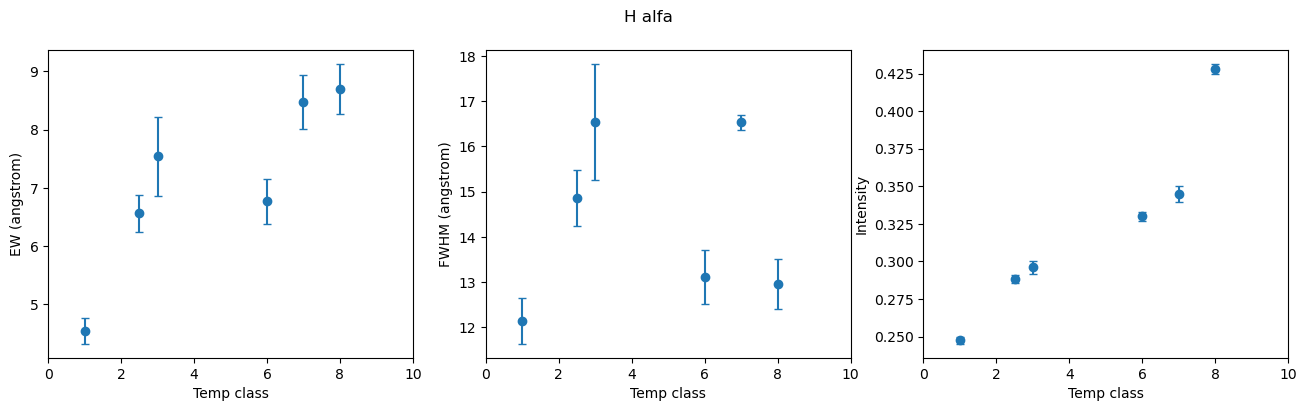

<Figure size 2200x600 with 0 Axes>

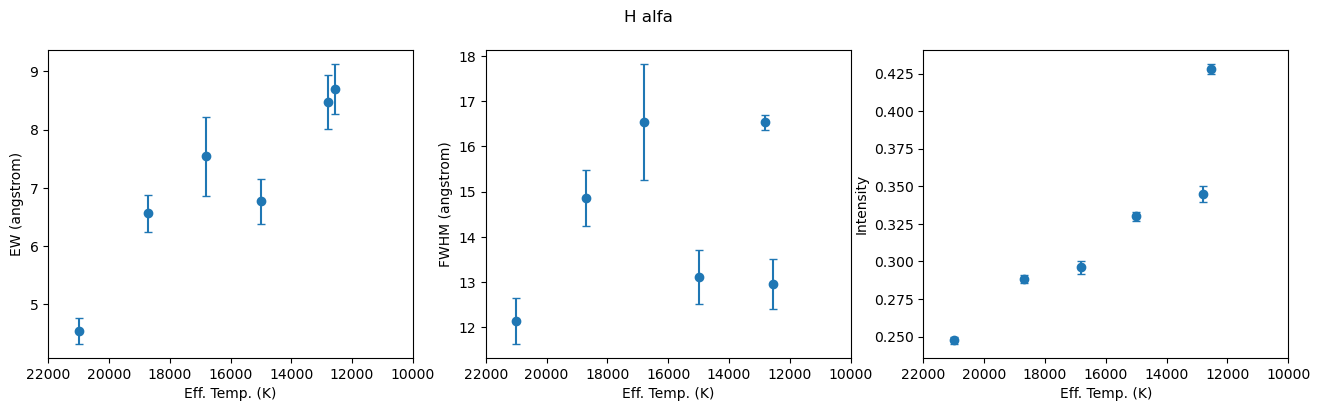

### Misura di H beta - 

<Figure size 2200x600 with 0 Axes>

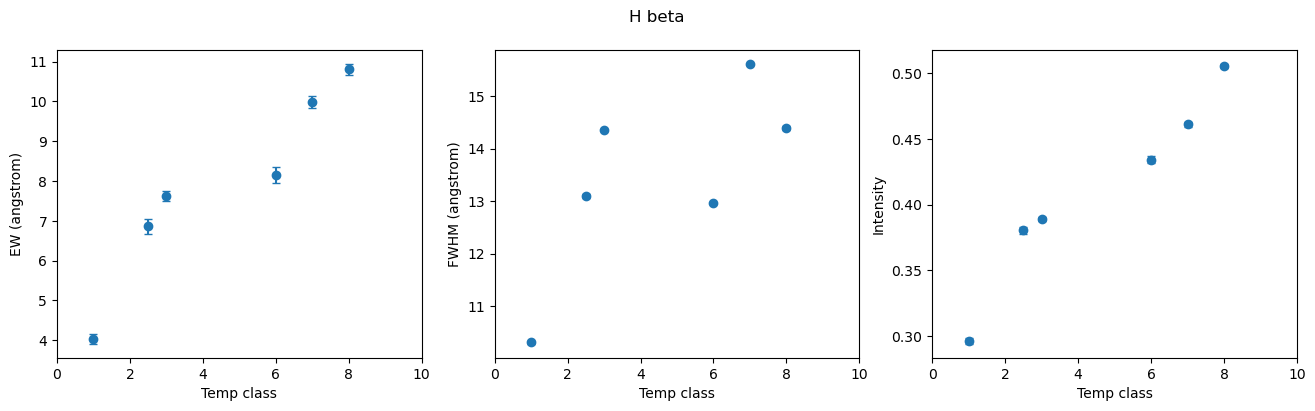

<Figure size 2200x600 with 0 Axes>

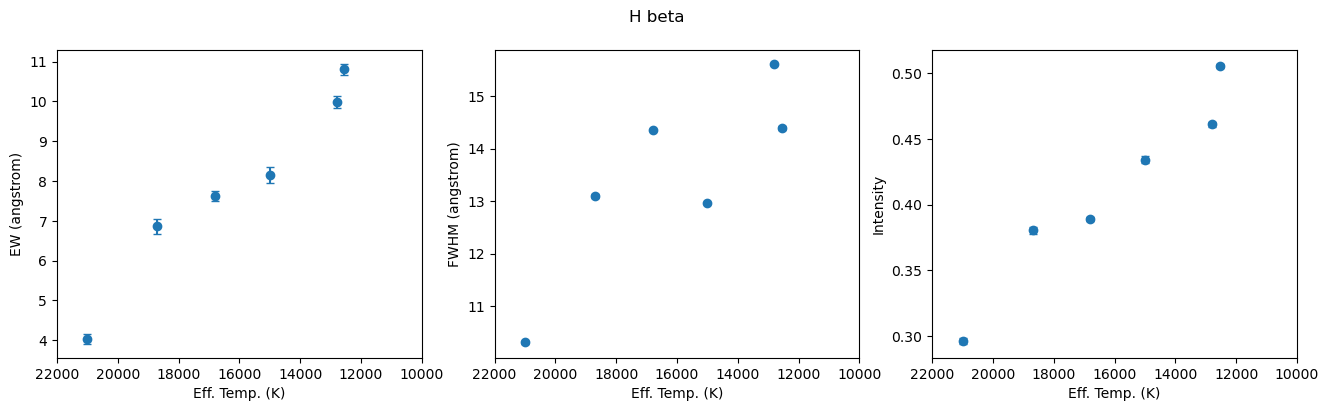

### Misura di H gamma - 

<Figure size 2200x600 with 0 Axes>

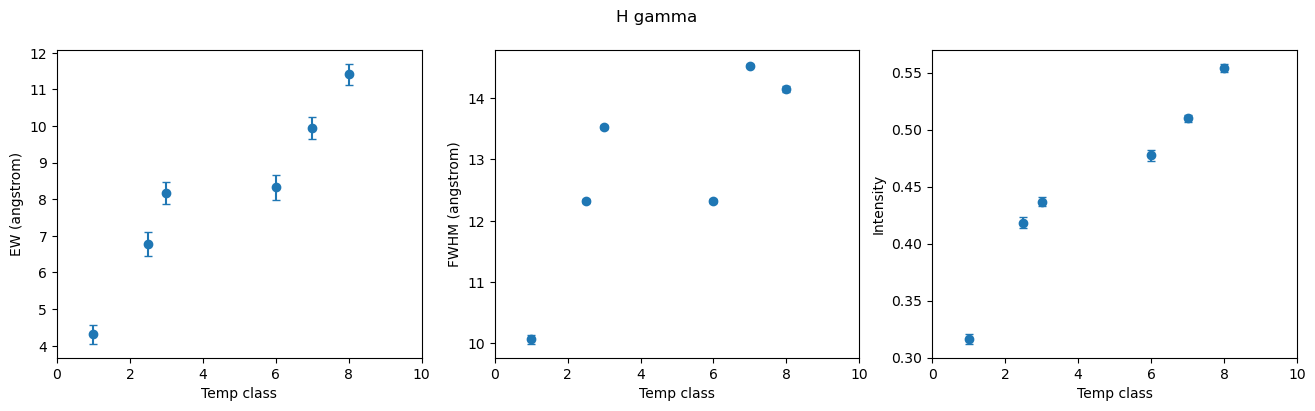

<Figure size 2200x600 with 0 Axes>

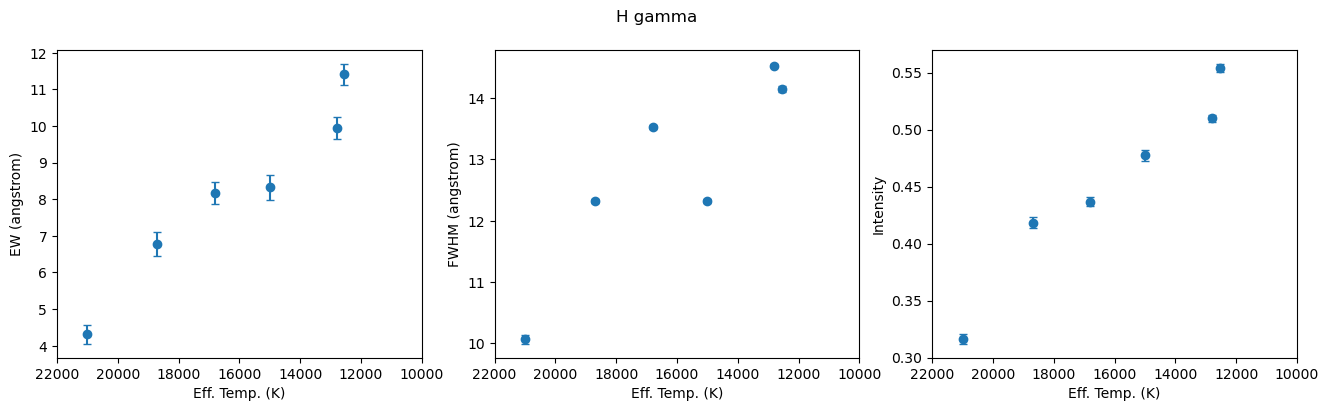

### Misura di H delta - 

<Figure size 2200x600 with 0 Axes>

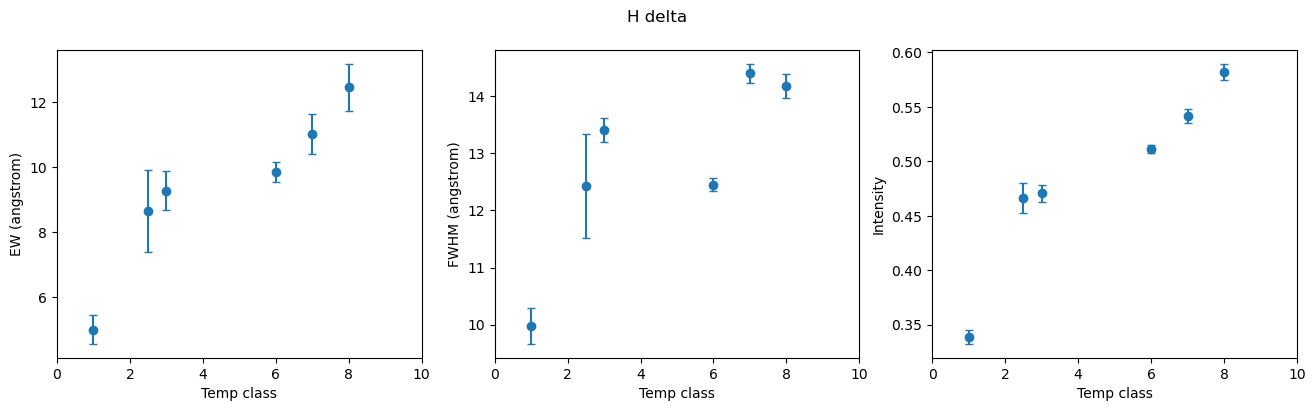

<Figure size 2200x600 with 0 Axes>

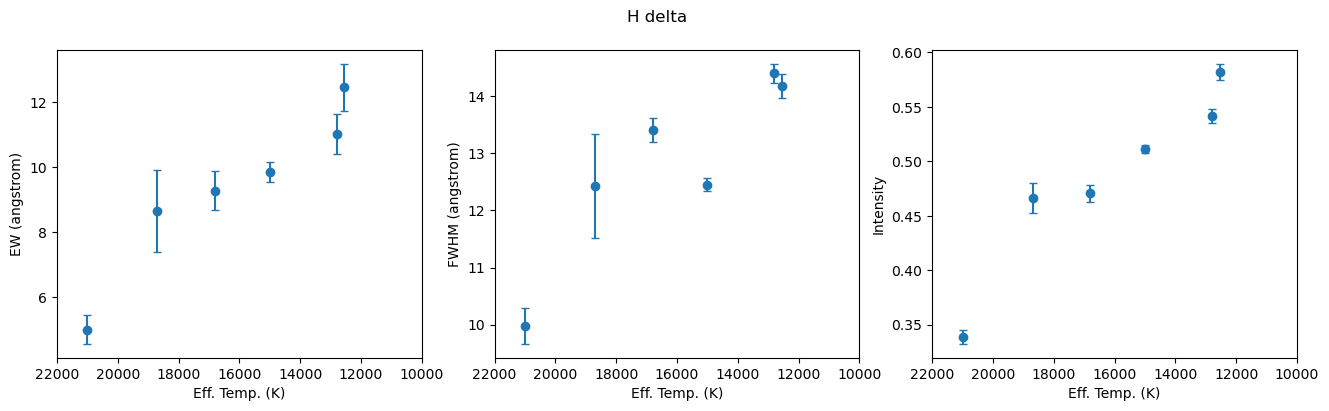

### Misura di He I 4026 - Tripletto 2p -> 5d

<Figure size 2200x600 with 0 Axes>

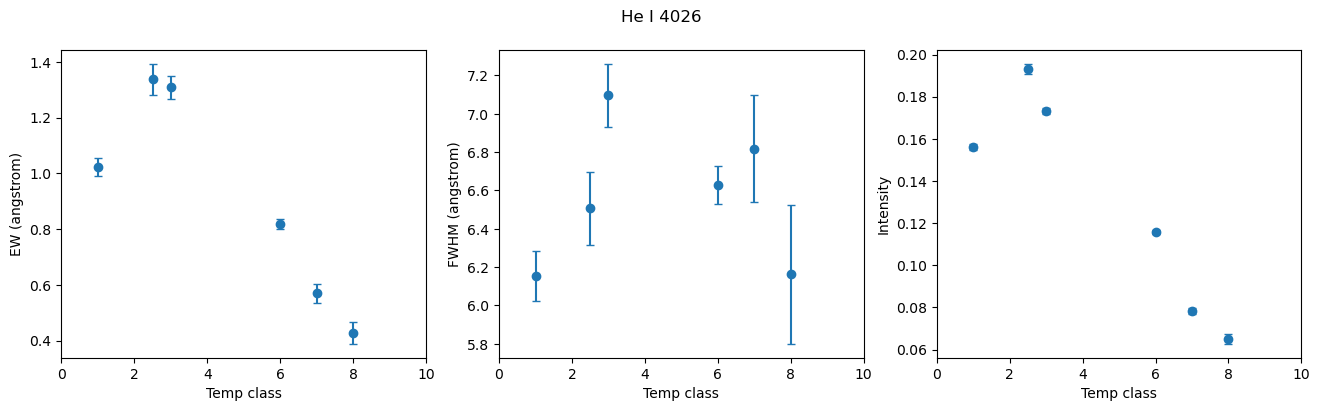

<Figure size 2200x600 with 0 Axes>

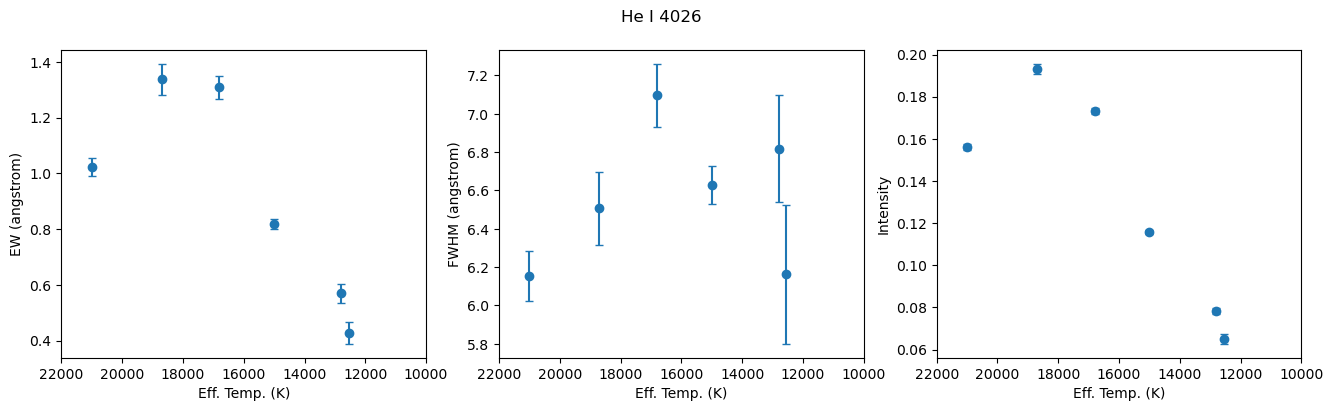

### Misura di He I 4388 - Singoletto 2p -> 5d

<Figure size 2200x600 with 0 Axes>

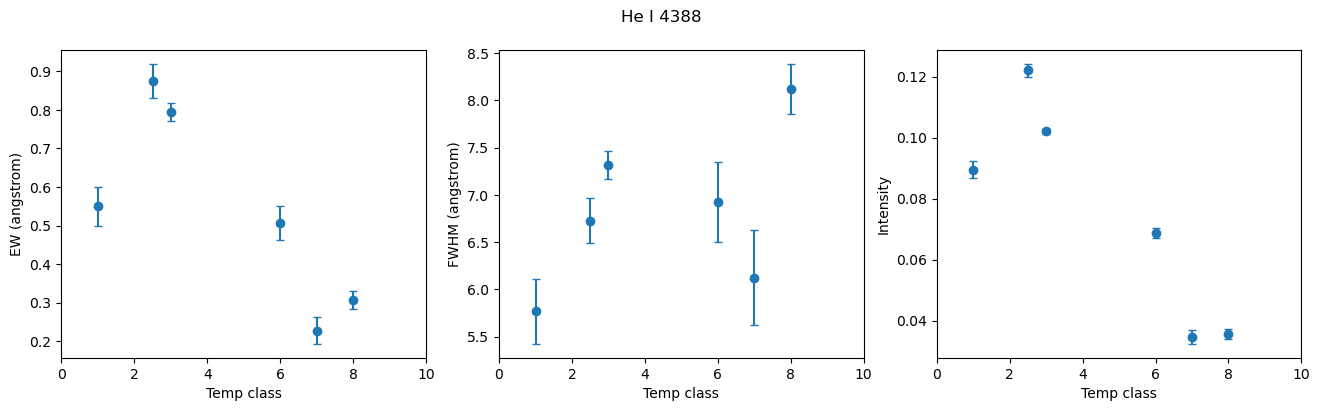

<Figure size 2200x600 with 0 Axes>

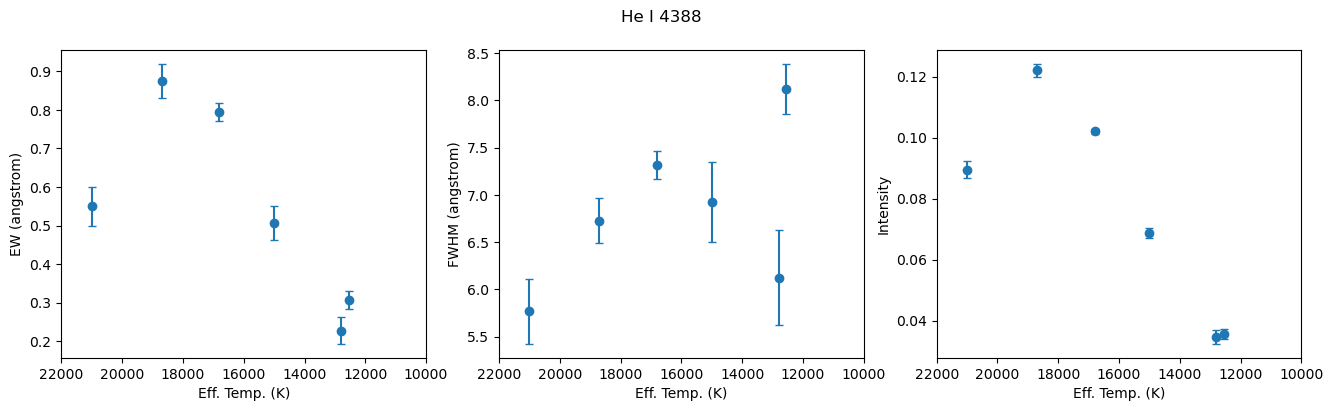

### Misura di He I 4471 - Tripletto 2p -> 4d

<Figure size 2200x600 with 0 Axes>

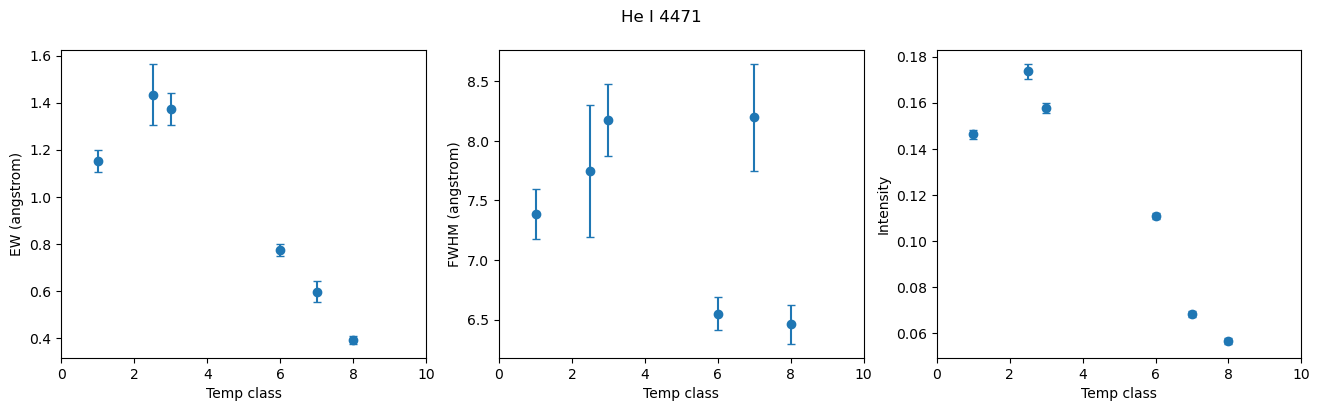

<Figure size 2200x600 with 0 Axes>

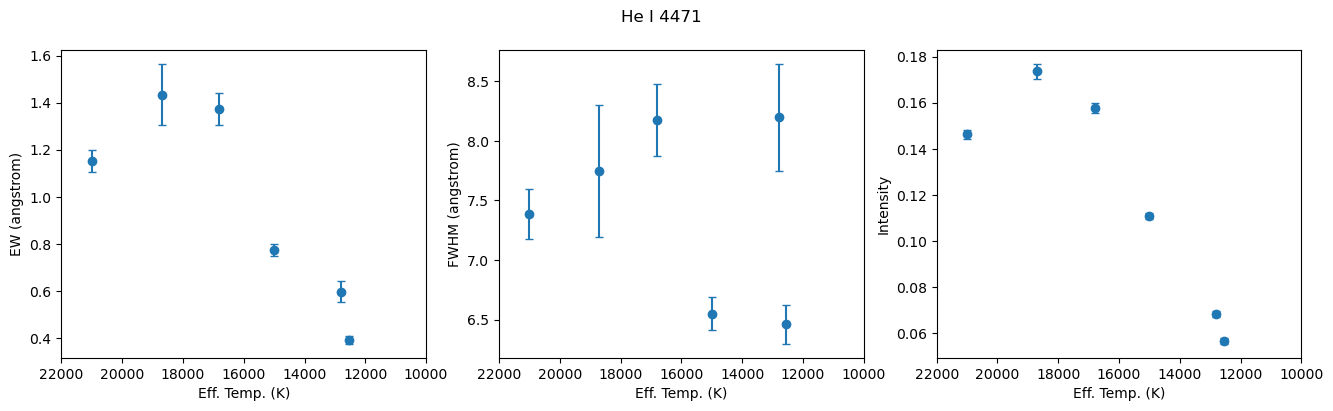

### Misura di He I 4922 - Singoletto 2p -> 4d

<Figure size 2200x600 with 0 Axes>

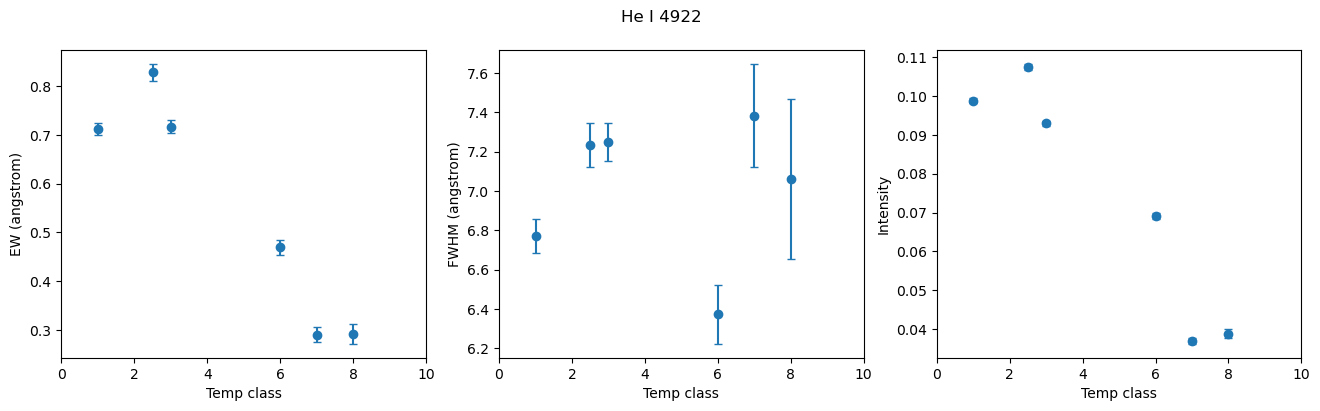

<Figure size 2200x600 with 0 Axes>

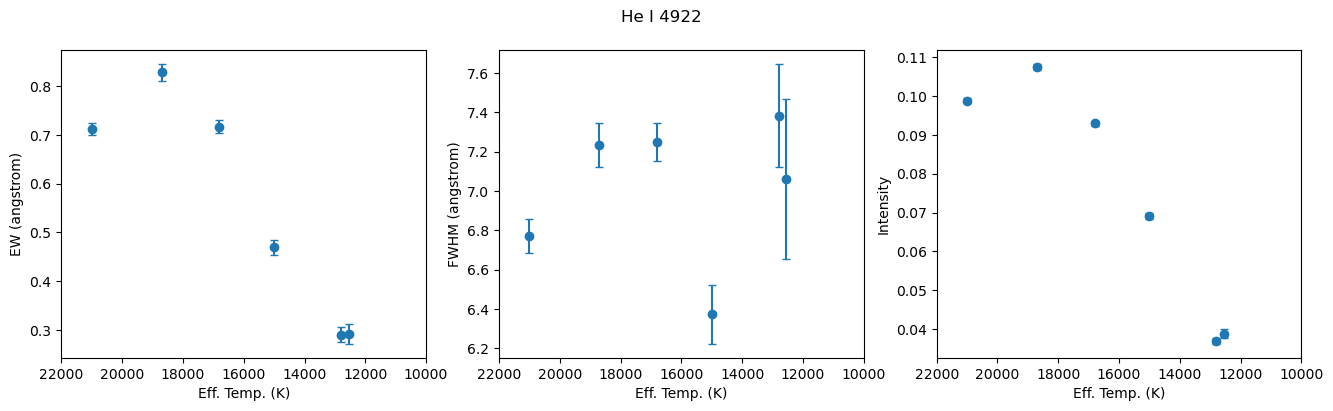

In [6]:
from IPython.display import Markdown, display

measured_lines = [{ "name":"H alfa",    "description":""},
                  { "name":"H beta",    "description":""},
                  { "name":"H gamma",   "description":""},
                  { "name":"H delta",   "description":""},
                  { "name":"He I 4026", "description":"Tripletto 2p -> 5d"},
                  { "name":"He I 4388", "description":"Singoletto 2p -> 5d"},
                  { "name":"He I 4471", "description":"Tripletto 2p -> 4d"},
                  { "name":"He I 4922", "description":"Singoletto 2p -> 4d"}]

measures = [
    { "col": "ew",        "err_col": "delta_ew",        "label": "EW (angstrom)" },
    { "col": "fwhm",      "err_col": "delta_fwhm",      "label": "FWHM (angstrom)" },
    { "col": "intensity", "err_col": "delta_intensity", "label": "Intensity" }
]

for line in measured_lines:
    line_name = line["name"]
    line_descr = line["description"]
    display(Markdown(f"### Misura di {line_name} - {line_descr}"))
    
    line_measures = all_measures[all_measures["line_name"] == line_name]
    line_measures = line_measures.sort_values(by=["temp index"], ascending=True)
    
    plt.figure(figsize=(22, 6))
    fig, axs = plt.subplots(nrows=1, ncols=len(measures), sharex=True)
    fig.set_figwidth(16)
    fig.set_figheight(4)
    fig.suptitle(line_name)
    i = 0
    for measure in measures:
        ax = axs[i]
        ax.set_xlabel("Temp class")
        ax.set_ylabel(measure["label"])
        ax.set_xlim(left=0.0, right=10.0)
        ax.errorbar(line_measures["temp index"], line_measures[measure["col"]], yerr=line_measures[measure["err_col"]], fmt="o", capsize=3)    
        i = i + 1
    plt.show()

    plt.figure(figsize=(22, 6))
    fig, axs = plt.subplots(nrows=1, ncols=len(measures), sharex=True)
    fig.set_figwidth(16)
    fig.set_figheight(4)
    fig.suptitle(line_name)
    i = 0
    for measure in measures:
        ax = axs[i]
        ax.set_xlabel("Eff. Temp. (K)")
        ax.set_ylabel(measure["label"])
        ax.set_xlim(left=22000.0, right=10000.0)
        ax.errorbar(line_measures["eff_temp"], line_measures[measure["col"]], yerr=line_measures[measure["err_col"]], fmt="o", capsize=3)    
        i = i + 1
    plt.show()